
# Propensity Score Matching + staggered DiD (manual Callaway & Sant'Anna-style implementation)

This notebook implements **PSM DiD with a staggered-treatment ATT(g,t) estimator** using the fixed analysis-ready panel already built in `ROOT/out`.

It is designed as **step 4** in the empirical workflow:

1. Baseline FE DiD (TWFE benchmark)
2. Staggered DiD (manual Callaway–Sant’Anna-style ATT(g,t), never-treated controls only)
3. Parallel-trends diagnostics
4. **Propensity Score Matching DiD + staggered ATT(g,t)**  ← this notebook
5. Augmented Synthetic Control / sensitivity checks

## Core design choices

- **Panel source:** `analysis_ready_panel_fixed.*`
- **Estimation window:** `2022Q1–2025Q4`
- **Control group:** **never-treated municipalities only**
- **Matching target:** municipality-level probability of being **ever treated**
- **Matching covariates:** common **pre-treatment** municipality averages only, taken from the window **2022Q1–2024Q1** so that no treated municipality contributes post-treatment information to the propensity score
- **Matching algorithm:** nearest-neighbor matching on the estimated propensity score, **with replacement**, using a **caliper on the logit propensity score**
- **Outcome estimand:** weighted ATT(g,t), aggregated to an overall ATT and a dynamic ATT(e)

The implementation is manual rather than package-based so every step is explicit and easy to audit.


In [1]:

from pathlib import Path
import math
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler

pd.set_option("display.max_columns", 200)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=RuntimeWarning)


In [2]:

def find_project_root(start: Path | None = None) -> Path:
    start = (start or Path.cwd()).resolve()
    for candidate in [start, *start.parents]:
        if (candidate / "data").exists() and (candidate / "src").exists():
            return candidate
    return start

ROOT = find_project_root()
OUT_DIR = ROOT / "out"
OUT_DIR.mkdir(parents=True, exist_ok=True)

candidate_paths = [
    OUT_DIR / "analysis_ready_panel_fixed.pkl",
    OUT_DIR / "analysis_ready_panel_fixed.jsonl",
    OUT_DIR / "analysis_ready_panel.pkl",
    OUT_DIR / "analysis_ready_panel.jsonl",
]

panel_path = next((p for p in candidate_paths if p.exists()), None)
if panel_path is None:
    raise FileNotFoundError(
        "Could not find an analysis-ready panel in ROOT/out. "
        f"Tried: {[p.name for p in candidate_paths]}"
    )

if panel_path.suffix == ".pkl":
    panel = pd.read_pickle(panel_path)
else:
    panel = pd.read_json(panel_path, orient="records", lines=True)

print("ROOT:", ROOT)
print("Loaded:", panel_path)
print("Shape:", panel.shape)
panel.head()


ROOT: /home/venatio/documents/university/public-sector-2026
Loaded: /home/venatio/documents/university/public-sector-2026/out/analysis_ready_panel.pkl
Shape: (56908, 61)


,Code,Municipality,municipality_norm,Year,Quarter,quarter_num,time_index,Prices,Contracts,price_observed_raw,contracts_observed_raw,price_imputed,contracts_imputed,has_any_observed_price,has_any_observed_contracts,exclude_from_price_analysis,exclude_from_contract_analysis,has_valid_price_for_analysis,has_valid_contracts_for_analysis,Treated 1,Treated 2,Control,ever_treated,cohort,first_treat_period,first_treat_index,treated,event_time,pop_total,pop_males,pop_females,pop_native_total,pop_native_males,pop_native_females,pop_foreign_total,pop_foreign_males,pop_foreign_females,mig_total,mig_total_males,mig_total_females,mig_inflows,mig_inflows_males,mig_inflows_females,mig_outflows,mig_outflows_males,mig_outflows_females,income_tax_base,income_tax_liability,log_prices,price_growth_qoq_pct,price_growth_yoy_pct,log_price_growth_qoq,log_price_growth_yoy,contracts_per_10k,contracts_per_10k_qoq_pct,contracts_per_10k_yoy_pct,rent_to_income_proxy,annualized_rent_to_income_proxy,rent_to_tax_liability_proxy,outcome_price_growth,outcome_market_activity
0,00005,NaN,,2015,Q1,1,8061,NaN,NaN,0,0,0,0,0,0,1,1,0,0,0,0,1,NaN,NaN,NaN,NaN,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,00005,NaN,,2015,Q2,2,8062,NaN,NaN,0,0,0,0,0,0,1,1,0,0,0,0,1,NaN,NaN,NaN,NaN,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,00005,NaN,,2015,Q3,3,8063,NaN,NaN,0,0,0,0,0,0,1,1,0,0,0,0,1,NaN,NaN,NaN,NaN,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,00005,NaN,,2015,Q4,4,8064,NaN,NaN,0,0,0,0,0,0,1,1,0,0,0,0,1,NaN,NaN,NaN,NaN,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,02050,NaN,,2011,Q1,1,8045,NaN,NaN,0,0,0,0,0,0,1,1,0,0,0,0,1,NaN,NaN,NaN,NaN,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [3]:

panel = panel.copy()
panel.columns = [str(c).strip() for c in panel.columns]

required_cols = [
    "Code", "Municipality", "Year", "Quarter", "quarter_num", "time_index",
    "ever_treated", "first_treat_index", "cohort",
    "outcome_price_growth", "outcome_market_activity",
    "rent_to_income_proxy", "contracts_per_10k", "price_growth_yoy_pct",
    "pop_total", "mig_total", "income_tax_base",
]
missing_required = [c for c in required_cols if c not in panel.columns]
if missing_required:
    raise ValueError(f"Missing required columns: {missing_required}")

panel["Code"] = panel["Code"].astype(str).str.zfill(5)
panel["Municipality"] = panel["Municipality"].astype(str).replace({"nan": np.nan}).str.strip()
panel = panel[panel["Municipality"].notna()].copy()

numeric_cols = [
    "Year", "quarter_num", "time_index", "ever_treated", "first_treat_index",
    "outcome_price_growth", "outcome_market_activity",
    "rent_to_income_proxy", "contracts_per_10k", "price_growth_yoy_pct",
    "pop_total", "mig_total", "income_tax_base",
    "has_valid_price_for_analysis", "has_valid_contracts_for_analysis",
]
for c in numeric_cols:
    if c in panel.columns:
        panel[c] = pd.to_numeric(panel[c], errors="coerce")

quarter_order = pd.CategoricalDtype(categories=["Q1", "Q2", "Q3", "Q4"], ordered=True)
panel["Quarter"] = panel["Quarter"].astype(quarter_order)

WINDOW_START = 2022 * 4 + 1
WINDOW_END = 2025 * 4 + 4
COMMON_PRE_END = 2024 * 4 + 1

panel = panel[(panel["time_index"] >= WINDOW_START) & (panel["time_index"] <= WINDOW_END)].copy()
panel = panel.sort_values(["Code", "time_index"]).reset_index(drop=True)

print("Windowed shape:", panel.shape)
print("Municipalities:", panel["Code"].nunique())
print("Time range:", panel["time_index"].min(), "to", panel["time_index"].max())
panel[["Code", "Municipality", "Year", "Quarter", "time_index", "ever_treated", "cohort"]].head()


Windowed shape: (15152, 61)
Municipalities: 947
Time range: 8089 to 8104


,Code,Municipality,Year,Quarter,time_index,ever_treated,cohort
0,08001,Abrera,2022,Q1,8089,1.0000,2024Q2
1,08001,Abrera,2022,Q2,8090,1.0000,2024Q2
2,08001,Abrera,2022,Q3,8091,1.0000,2024Q2
3,08001,Abrera,2022,Q4,8092,1.0000,2024Q2
4,08001,Abrera,2023,Q1,8093,1.0000,2024Q2



## Matching strategy

The propensity score is estimated at the **municipality level**, using only **common pre-treatment information** from `2022Q1–2024Q1`.

This avoids any contamination from post-treatment outcomes or controls.

The matching is run separately for:

- **Rent-growth analysis sample**
- **Tenancy-agreements analysis sample**

because the rent outcome has a narrower valid-data sample than the contracts outcome.


In [4]:

def _first_nonmissing(series):
    s = series.dropna()
    return s.iloc[0] if len(s) else np.nan

def phi(z):
    if pd.isna(z):
        return np.nan
    return 0.5 * (1 + math.erf(z / np.sqrt(2)))

def stars_from_p(p):
    if pd.isna(p):
        return ""
    if p < 0.01:
        return "***"
    if p < 0.05:
        return "**"
    if p < 0.10:
        return "*"
    return ""

def weighted_mean(x, w):
    x = pd.to_numeric(pd.Series(x), errors="coerce")
    w = pd.to_numeric(pd.Series(w), errors="coerce")
    mask = x.notna() & w.notna() & (w > 0)
    if mask.sum() == 0:
        return np.nan
    return np.average(x[mask], weights=w[mask])

def weighted_var(x, w):
    x = pd.to_numeric(pd.Series(x), errors="coerce")
    w = pd.to_numeric(pd.Series(w), errors="coerce")
    mask = x.notna() & w.notna() & (w > 0)
    if mask.sum() <= 1:
        return np.nan
    x = x[mask]
    w = w[mask]
    mu = np.average(x, weights=w)
    return np.average((x - mu) ** 2, weights=w)

def smd_unweighted(treated, control):
    treated = pd.to_numeric(pd.Series(treated), errors="coerce").dropna()
    control = pd.to_numeric(pd.Series(control), errors="coerce").dropna()
    if len(treated) == 0 or len(control) == 0:
        return np.nan
    mt = treated.mean()
    mc = control.mean()
    vt = treated.var(ddof=1)
    vc = control.var(ddof=1)
    denom = np.sqrt((vt + vc) / 2)
    if denom == 0 or pd.isna(denom):
        return np.nan
    return (mt - mc) / denom

def smd_weighted(treated, control, control_w):
    treated = pd.to_numeric(pd.Series(treated), errors="coerce")
    control = pd.to_numeric(pd.Series(control), errors="coerce")
    control_w = pd.to_numeric(pd.Series(control_w), errors="coerce")
    tmask = treated.notna()
    cmask = control.notna() & control_w.notna() & (control_w > 0)
    if tmask.sum() == 0 or cmask.sum() == 0:
        return np.nan
    mt = treated[tmask].mean()
    vt = treated[tmask].var(ddof=1)

    mc = weighted_mean(control[cmask], control_w[cmask])
    vc = weighted_var(control[cmask], control_w[cmask])

    denom = np.sqrt((vt + vc) / 2)
    if denom == 0 or pd.isna(denom):
        return np.nan
    return (mt - mc) / denom


In [5]:
def build_unit_level_dataset(
    panel_df: pd.DataFrame,
    outcome_col: str,
    valid_flag_col: str,
    additional_pre_cols: list[str],
    common_pre_end: int = COMMON_PRE_END,
) -> pd.DataFrame:
    cols_needed = [
        "Code", "Municipality", "ever_treated", "first_treat_index", "cohort",
        "time_index", outcome_col, valid_flag_col,
    ] + additional_pre_cols

    tmp = panel_df[cols_needed].copy()
    tmp = tmp[tmp[valid_flag_col] == 1].copy()

    pre = tmp[tmp["time_index"] <= common_pre_end].copy()

    unit_meta = (
        pre.groupby("Code", as_index=False)
        .agg(
            Municipality=("Municipality", _first_nonmissing),
            ever_treated=("ever_treated", "max"),
            first_treat_index=("first_treat_index", _first_nonmissing),
            cohort=("cohort", _first_nonmissing),
            n_pre_rows=("time_index", "nunique"),
        )
    )

    pre_outcome = (
        pre.groupby("Code", as_index=False)[outcome_col]
        .mean()
        .rename(columns={outcome_col: "pre_outcome_mean"})
    )

    covar_aggs = (
        pre.groupby("Code", as_index=False)[additional_pre_cols]
        .mean()
        .rename(columns={c: f"pre_{c}" for c in additional_pre_cols})
    )

    out = unit_meta.merge(pre_outcome, on="Code", how="left").merge(covar_aggs, on="Code", how="left")
    out = out[out["ever_treated"].isin([0, 1])].copy()
    out["ever_treated"] = out["ever_treated"].astype(int)
    out = out[out["n_pre_rows"] >= 4].copy()
    return out.reset_index(drop=True)

def prepare_psm_design(unit_df: pd.DataFrame, covariate_cols: list[str]):
    X = pd.DataFrame(index=unit_df.index)
    for c in covariate_cols:
        s = pd.to_numeric(unit_df[c], errors="coerce")
        if s.isna().any():
            X[f"{c}__missing"] = s.isna().astype(int)
        fill_value = s.median()
        X[c] = s.fillna(fill_value)
    return X

def estimate_propensity_scores(unit_df: pd.DataFrame, covariate_cols: list[str]) -> tuple[pd.DataFrame, list[str]]:
    X = prepare_psm_design(unit_df, covariate_cols)
    y = unit_df["ever_treated"].astype(int)

    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(X)

    model = LogisticRegression(
        penalty="l2",
        C=1.0,
        solver="lbfgs",
        max_iter=5000,
        random_state=42,
    )
    model.fit(X_scaled, y)

    pscore = model.predict_proba(X_scaled)[:, 1]
    pscore = np.clip(pscore, 1e-6, 1 - 1e-6)

    out = unit_df.copy()
    out["pscore"] = pscore
    out["logit_pscore"] = np.log(out["pscore"] / (1 - out["pscore"]))
    return out, list(X.columns)

def apply_common_support(unit_df: pd.DataFrame) -> pd.DataFrame:
    treated = unit_df[unit_df["ever_treated"] == 1].copy()
    controls = unit_df[unit_df["ever_treated"] == 0].copy()

    lower = max(treated["pscore"].min(), controls["pscore"].min())
    upper = min(treated["pscore"].max(), controls["pscore"].max())

    out = unit_df[(unit_df["pscore"] >= lower) & (unit_df["pscore"] <= upper)].copy()
    out["in_common_support"] = 1
    return out.reset_index(drop=True)

def nearest_neighbor_match(unit_df: pd.DataFrame, n_matches: int = 3, caliper_mult: float = 0.2):
    treated = unit_df[unit_df["ever_treated"] == 1].copy().reset_index(drop=True)
    controls = unit_df[unit_df["ever_treated"] == 0].copy().reset_index(drop=True)

    if treated.empty or controls.empty:
        raise ValueError("Need both treated and never-treated units after common support.")

    caliper_sd = np.nanstd(unit_df["logit_pscore"], ddof=1)
    caliper = np.inf if pd.isna(caliper_sd) or caliper_sd == 0 else caliper_mult * caliper_sd

    control_use_counts = {code: 0.0 for code in controls["Code"]}
    treated_keep = []
    match_rows = []

    for _, tr in treated.iterrows():
        diffs = np.abs(controls["logit_pscore"] - tr["logit_pscore"])
        within = controls.loc[diffs <= caliper].copy()
        if within.empty:
            continue

        within["abs_diff"] = np.abs(within["logit_pscore"] - tr["logit_pscore"])
        within = within.sort_values(["abs_diff", "pscore", "Code"]).head(n_matches).copy()

        k = len(within)
        if k == 0:
            continue

        treated_keep.append(tr["Code"])
        for _, co in within.iterrows():
            control_use_counts[co["Code"]] += 1.0 / k
            match_rows.append({
                "treated_code": tr["Code"],
                "control_code": co["Code"],
                "treated_pscore": tr["pscore"],
                "control_pscore": co["pscore"],
                "abs_pscore_diff": abs(tr["pscore"] - co["pscore"]),
                "abs_logit_diff": abs(tr["logit_pscore"] - co["logit_pscore"]),
            })

    if not treated_keep:
        raise ValueError("No treated units found a control within the caliper.")

    treated_keep = pd.Series(treated_keep).drop_duplicates().tolist()
    matched_controls = {k: v for k, v in control_use_counts.items() if v > 0}

    out = unit_df.copy()
    out["match_weight"] = 0.0
    out.loc[(out["ever_treated"] == 1) & (out["Code"].isin(treated_keep)), "match_weight"] = 1.0
    for code, w in matched_controls.items():
        out.loc[out["Code"] == code, "match_weight"] = w

    out["matched_sample"] = (out["match_weight"] > 0).astype(int)
    out = out[out["matched_sample"] == 1].copy().reset_index(drop=True)
    pair_df = pd.DataFrame(match_rows)
    return out, pair_df

def build_balance_table(unit_before, unit_after, covariate_cols):
    rows = []
    for c in covariate_cols:
        t_before = unit_before.loc[unit_before["ever_treated"] == 1, c]
        c_before = unit_before.loc[unit_before["ever_treated"] == 0, c]
        smd_before = smd_unweighted(t_before, c_before)

        t_after = unit_after.loc[unit_after["ever_treated"] == 1, c]
        c_after = unit_after.loc[unit_after["ever_treated"] == 0, c]
        w_after = unit_after.loc[unit_after["ever_treated"] == 0, "match_weight"]

        smd_after = smd_weighted(t_after, c_after, w_after)

        rows.append({
            "covariate": c,
            "treated_mean_before": pd.to_numeric(t_before, errors="coerce").mean(),
            "control_mean_before": pd.to_numeric(c_before, errors="coerce").mean(),
            "smd_before": smd_before,
            "treated_mean_after": pd.to_numeric(t_after, errors="coerce").mean(),
            "control_mean_after_weighted": weighted_mean(c_after, w_after),
            "smd_after": smd_after,
            "abs_smd_reduction": abs(smd_before) - abs(smd_after) if pd.notna(smd_before) and pd.notna(smd_after) else np.nan,
        })
    return pd.DataFrame(rows)


## Manual ATT(g,t) estimator on the matched sample

This follows the same logic as the previous manual staggered DiD notebook:

- compare each treated cohort `g` to **never-treated matched controls**
- use `g-1` as the reference period
- compute cohort-time ATT(g,t) only for `t >= g`
- aggregate to:
  - an **overall ATT**
  - a **dynamic ATT(e)** by event time


In [6]:
def make_matched_panel(panel_df: pd.DataFrame, matched_units: pd.DataFrame) -> pd.DataFrame:
    keep_cols = ["Code", "match_weight", "matched_sample", "pscore", "logit_pscore", "ever_treated", "first_treat_index", "cohort"]
    out = panel_df.merge(
        matched_units[keep_cols].drop_duplicates("Code"),
        on=["Code", "ever_treated", "first_treat_index", "cohort"],
        how="inner",
    )
    out = out[out["matched_sample"] == 1].copy()
    out = out.sort_values(["Code", "time_index"]).reset_index(drop=True)
    return out

def estimate_att_gt_weighted(df: pd.DataFrame, outcome_col: str, unit_col: str = "Code", weight_col: str = "match_weight") -> pd.DataFrame:
    df = df.copy()
    df[outcome_col] = pd.to_numeric(df[outcome_col], errors="coerce")
    df[weight_col] = pd.to_numeric(df[weight_col], errors="coerce")

    cohorts = sorted(df.loc[df["ever_treated"] == 1, "first_treat_index"].dropna().unique())
    periods = sorted(df["time_index"].dropna().unique())
    controls = df[df["ever_treated"] == 0].copy()

    out_rows = []
    for g in cohorts:
        ref = g - 1
        if ref not in periods:
            continue

        treated_ids = df.loc[(df["ever_treated"] == 1) & (df["first_treat_index"] == g), unit_col].dropna().unique()
        treated_df = df[df[unit_col].isin(treated_ids)].copy()

        for t in periods:
            if t < g:
                continue

            tr_ref = treated_df.loc[treated_df["time_index"] == ref, [unit_col, outcome_col, weight_col]].rename(columns={outcome_col: "y_ref", weight_col: "w_ref"})
            tr_t = treated_df.loc[treated_df["time_index"] == t, [unit_col, outcome_col, weight_col]].rename(columns={outcome_col: "y_t", weight_col: "w_t"})
            tr = tr_ref.merge(tr_t, on=unit_col, how="inner").dropna(subset=["y_ref", "y_t"])
            if tr.empty:
                continue

            treated_change = (tr["y_t"] - tr["y_ref"]).mean()
            n_treated = tr[unit_col].nunique()

            co_ref = controls.loc[controls["time_index"] == ref, [unit_col, outcome_col, weight_col]].rename(columns={outcome_col: "y_ref", weight_col: "w_ref"})
            co_t = controls.loc[controls["time_index"] == t, [unit_col, outcome_col, weight_col]].rename(columns={outcome_col: "y_t", weight_col: "w_t"})
            co = co_ref.merge(co_t, on=unit_col, how="inner").dropna(subset=["y_ref", "y_t", "w_ref"])
            if co.empty:
                continue

            control_change = weighted_mean(co["y_t"] - co["y_ref"], co["w_ref"])
            n_controls_weight = co["w_ref"].sum()

            out_rows.append({
                "cohort_index": g,
                "period_index": t,
                "event_time": t - g,
                "ref_period_index": ref,
                "att": treated_change - control_change,
                "n_treated": n_treated,
                "n_treated_weight": float(n_treated),
                "n_control_weight": float(n_controls_weight),
            })

    return pd.DataFrame(out_rows)

def aggregate_overall(att_gt: pd.DataFrame) -> pd.DataFrame:
    if att_gt.empty:
        return pd.DataFrame(columns=["att", "n_cells", "n_treated_weight"])
    w = att_gt["n_treated_weight"]
    att = weighted_mean(att_gt["att"], w)
    return pd.DataFrame([{
        "att": att,
        "n_cells": len(att_gt),
        "n_treated_weight": w.sum(),
    }])

def aggregate_dynamic(att_gt: pd.DataFrame) -> pd.DataFrame:
    if att_gt.empty:
        return pd.DataFrame(columns=["event_time", "att", "n_cells", "n_treated_weight"])
    rows = []
    for e, g in att_gt.groupby("event_time"):
        w = g["n_treated_weight"]
        rows.append({
            "event_time": e,
            "att": weighted_mean(g["att"], w),
            "n_cells": len(g),
            "n_treated_weight": w.sum(),
        })
    return pd.DataFrame(rows).sort_values("event_time").reset_index(drop=True)

In [7]:
def bootstrap_panel_by_unit(df: pd.DataFrame, unit_col: str = "Code", seed: int = 42) -> pd.DataFrame:
    rng = np.random.default_rng(seed)
    units = df[unit_col].dropna().unique()
    sampled = rng.choice(units, size=len(units), replace=True)

    boot_parts = []
    for i, u in enumerate(sampled):
        part = df.loc[df[unit_col] == u].copy()
        part[unit_col] = f"{u}__b{i}"
        boot_parts.append(part)

    return pd.concat(boot_parts, ignore_index=True)

def attach_bootstrap_inference(point_overall: pd.DataFrame, overall_boot: np.ndarray) -> pd.DataFrame:
    out = point_overall.copy()
    se = np.nanstd(np.asarray(overall_boot, dtype=float), ddof=1)
    out["se"] = se
    out["z"] = np.where(out["se"].notna() & (out["se"] > 0), out["att"] / out["se"], np.nan)
    out["p_value"] = 2 * (1 - pd.Series(out["z"]).abs().map(phi))
    out["ci_low"] = out["att"] - 1.96 * out["se"]
    out["ci_high"] = out["att"] + 1.96 * out["se"]
    out["att_stars"] = out.apply(lambda r: f"{r['att']:.4f}{stars_from_p(r['p_value'])}" if pd.notna(r["att"]) else np.nan, axis=1)
    return out

def attach_dynamic_bootstrap_inference(point_dynamic: pd.DataFrame, dynamic_boot_rows: list[pd.DataFrame]) -> pd.DataFrame:
    out = point_dynamic.copy()
    if dynamic_boot_rows:
        dynamic_boot = pd.concat(dynamic_boot_rows, ignore_index=True)
        dynamic_se = (
            dynamic_boot.groupby("event_time")["att"]
            .std(ddof=1)
            .rename("se")
            .reset_index()
        )
        out = out.merge(dynamic_se, on="event_time", how="left")
        out["ci_low"] = out["att"] - 1.96 * out["se"]
        out["ci_high"] = out["att"] + 1.96 * out["se"]
    else:
        out["se"] = np.nan
        out["ci_low"] = np.nan
        out["ci_high"] = np.nan
    return out

def run_psm_csdid_pipeline(
    panel_df: pd.DataFrame,
    outcome_col: str,
    valid_flag_col: str,
    matching_covariates: list[str],
    label: str,
    n_matches: int = 3,
    caliper_mult: float = 0.2,
    boot_reps: int = 199,
    boot_seed: int = 42,
):
    unit_df = build_unit_level_dataset(
        panel_df=panel_df,
        outcome_col=outcome_col,
        valid_flag_col=valid_flag_col,
        additional_pre_cols=matching_covariates,
    )

    covariate_cols = ["pre_outcome_mean"] + [f"pre_{c}" for c in matching_covariates]
    unit_ps, design_cols = estimate_propensity_scores(unit_df, covariate_cols)
    unit_ps_cs = apply_common_support(unit_ps)
    matched_units, matched_pairs = nearest_neighbor_match(unit_ps_cs, n_matches=n_matches, caliper_mult=caliper_mult)
    balance = build_balance_table(unit_ps_cs, matched_units, covariate_cols)

    matched_panel = make_matched_panel(panel_df, matched_units)
    att_gt = estimate_att_gt_weighted(matched_panel, outcome_col, unit_col="Code", weight_col="match_weight")
    overall = aggregate_overall(att_gt)
    dynamic = aggregate_dynamic(att_gt)

    overall_boot = []
    dynamic_boot_rows = []

    for b in range(boot_reps):
        boot_panel = bootstrap_panel_by_unit(panel_df, unit_col="Code", seed=boot_seed + b + 1)
        try:
            boot_unit = build_unit_level_dataset(
                panel_df=boot_panel,
                outcome_col=outcome_col,
                valid_flag_col=valid_flag_col,
                additional_pre_cols=matching_covariates,
            )
            boot_unit_ps, _ = estimate_propensity_scores(boot_unit, covariate_cols)
            boot_unit_ps_cs = apply_common_support(boot_unit_ps)
            boot_matched_units, _ = nearest_neighbor_match(boot_unit_ps_cs, n_matches=n_matches, caliper_mult=caliper_mult)
            boot_matched_panel = make_matched_panel(boot_panel, boot_matched_units)
            boot_att_gt = estimate_att_gt_weighted(boot_matched_panel, outcome_col, unit_col="Code", weight_col="match_weight")
            boot_overall = aggregate_overall(boot_att_gt)
            boot_dynamic = aggregate_dynamic(boot_att_gt)

            overall_boot.append(boot_overall.iloc[0]["att"] if not boot_overall.empty else np.nan)

            if not dynamic.empty:
                merged = dynamic[["event_time"]].merge(boot_dynamic[["event_time", "att"]], on="event_time", how="left")
                merged["rep"] = b
                dynamic_boot_rows.append(merged)
        except Exception:
            overall_boot.append(np.nan)
            if not dynamic.empty:
                merged = dynamic[["event_time"]].copy()
                merged["att"] = np.nan
                merged["rep"] = b
                dynamic_boot_rows.append(merged)

    overall = attach_bootstrap_inference(overall, np.asarray(overall_boot, dtype=float))
    dynamic = attach_dynamic_bootstrap_inference(dynamic, dynamic_boot_rows)

    summary = overall.copy()
    summary.insert(0, "Outcome", label)
    summary["N municipalities (matched)"] = matched_units["Code"].nunique()
    summary["N treated (matched)"] = matched_units.loc[matched_units["ever_treated"] == 1, "Code"].nunique()
    summary["N controls (matched)"] = matched_units.loc[matched_units["ever_treated"] == 0, "Code"].nunique()
    summary["Matching"] = f"{n_matches}:1 nearest-neighbor, replacement"
    summary["Caliper rule"] = f"{caliper_mult:.2f} * SD(logit pscore)"
    summary["Control group"] = "Never treated only"
    summary["Estimation window"] = "2022Q1-2025Q4"
    summary["Bootstrap reps"] = boot_reps

    artifacts = {
        "unit_ps": unit_ps,
        "unit_ps_common_support": unit_ps_cs,
        "matched_units": matched_units,
        "matched_pairs": matched_pairs,
        "balance": balance,
        "matched_panel": matched_panel,
        "att_gt": att_gt,
        "overall": overall,
        "dynamic": dynamic,
        "summary": summary,
        "overall_boot": np.asarray(overall_boot, dtype=float),
    }
    return artifacts

In [8]:
RENT_MATCH_COVARS = [
    "contracts_per_10k",
    "rent_to_income_proxy",
    "pop_total",
    "income_tax_base",
]

CONTRACTS_MATCH_COVARS = [
    "price_growth_yoy_pct",
    "rent_to_income_proxy",
    "pop_total",
    "income_tax_base",
]

BOOT_REPS = 199
N_MATCHES = 3
CALIPER_MULT = 0.1

print("Bootstrap reps:", BOOT_REPS)
print("Matching ratio:", N_MATCHES)
print("Caliper multiplier:", CALIPER_MULT)

Bootstrap reps: 199
Matching ratio: 3
Caliper multiplier: 0.1


## Rent-growth PSM + staggered DiD

In [9]:
rent_results = run_psm_csdid_pipeline(
    panel_df=panel,
    outcome_col="outcome_price_growth",
    valid_flag_col="has_valid_price_for_analysis",
    matching_covariates=RENT_MATCH_COVARS,
    label="Rent growth (YoY, pp)",
    n_matches=N_MATCHES,
    caliper_mult=CALIPER_MULT,
    boot_reps=BOOT_REPS,
    boot_seed=42,
)

display(rent_results["summary"])
display(rent_results["balance"])

,Outcome,att,n_cells,n_treated_weight,se,z,p_value,ci_low,ci_high,att_stars,N municipalities (matched),N treated (matched),N controls (matched),Matching,Caliper rule,Control group,Estimation window,Bootstrap reps
0,"Rent growth (YoY, pp)",-6.7687,11,"1,030.0000",3.0257,-2.2371,0.0253,-12.6991,-0.8384,-6.7687**,361,202,159,"3:1 nearest-neighbor, replacement",0.10 * SD(logit pscore),Never treated only,2022Q1-2025Q4,199


,covariate,treated_mean_before,control_mean_before,smd_before,treated_mean_after,control_mean_after_weighted,smd_after,abs_smd_reduction
0,pre_outcome_mean,6.7359,5.5421,0.2138,6.7169,8.4366,-0.2620,-0.0482
1,pre_contracts_per_10k,36.2253,32.1075,0.2817,35.1861,36.1703,-0.0646,0.2171
2,pre_rent_to_income_proxy,0.0250,0.0229,0.4851,0.0246,0.0263,-0.3327,0.1524
3,pre_pop_total,"9,913.9274","2,426.4539",1.2258,"8,480.5094","4,048.6681",0.6681,0.5577
4,pre_income_tax_base,"25,666.0772","24,469.5994",0.2590,"25,380.0682","25,752.0432",-0.0743,0.1847


## Tenancy-agreements PSM + staggered DiD

In [10]:
contracts_results = run_psm_csdid_pipeline(
    panel_df=panel,
    outcome_col="outcome_market_activity",
    valid_flag_col="has_valid_contracts_for_analysis",
    matching_covariates=CONTRACTS_MATCH_COVARS,
    label="Tenancy agreements per 10k",
    n_matches=N_MATCHES,
    caliper_mult=CALIPER_MULT,
    boot_reps=BOOT_REPS,
    boot_seed=10042,
)

display(contracts_results["summary"])
display(contracts_results["balance"])

,Outcome,att,n_cells,n_treated_weight,se,z,p_value,ci_low,ci_high,att_stars,N municipalities (matched),N treated (matched),N controls (matched),Matching,Caliper rule,Control group,Estimation window,Bootstrap reps
0,Tenancy agreements per 10k,-2.9048,11,956.0000,2.4477,-1.1867,0.2353,-7.7024,1.8928,-2.9048,341,191,150,"3:1 nearest-neighbor, replacement",0.10 * SD(logit pscore),Never treated only,2022Q1-2025Q4,199


,covariate,treated_mean_before,control_mean_before,smd_before,treated_mean_after,control_mean_after_weighted,smd_after,abs_smd_reduction
0,pre_outcome_mean,35.7464,32.2020,0.2416,34.6364,39.9062,-0.2918,-0.0502
1,pre_price_growth_yoy_pct,6.6678,5.6229,0.1856,6.5735,9.5234,-0.4567,-0.2712
2,pre_rent_to_income_proxy,0.0249,0.0230,0.4425,0.0245,0.0259,-0.2999,0.1426
3,pre_pop_total,"8,511.9928","2,449.1893",1.2853,"7,907.2676","3,944.9422",0.6962,0.5891
4,pre_income_tax_base,"25,751.9506","24,476.5834",0.2725,"25,422.0448","25,004.0855",0.0908,0.1817


## Quick overlap and balance diagnostics

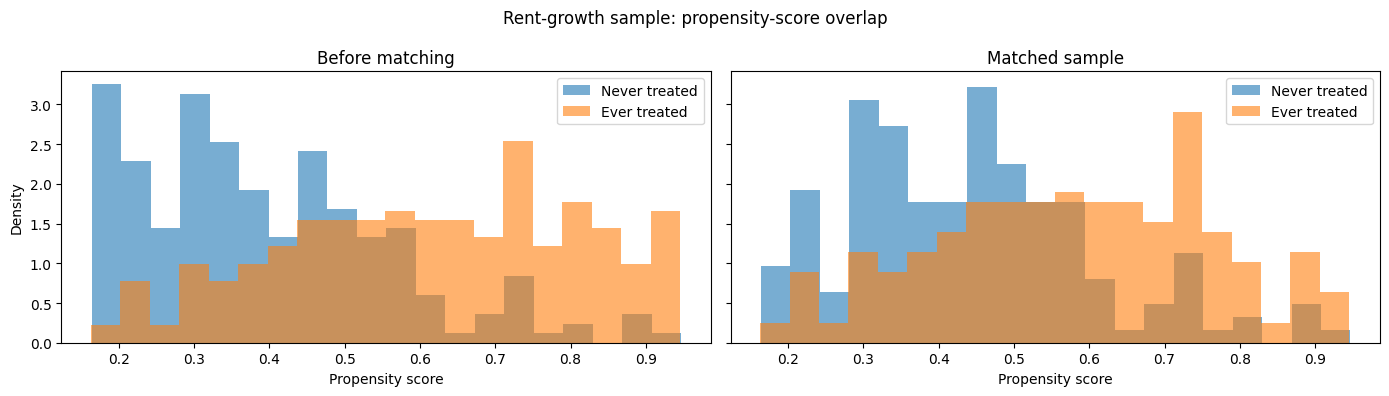

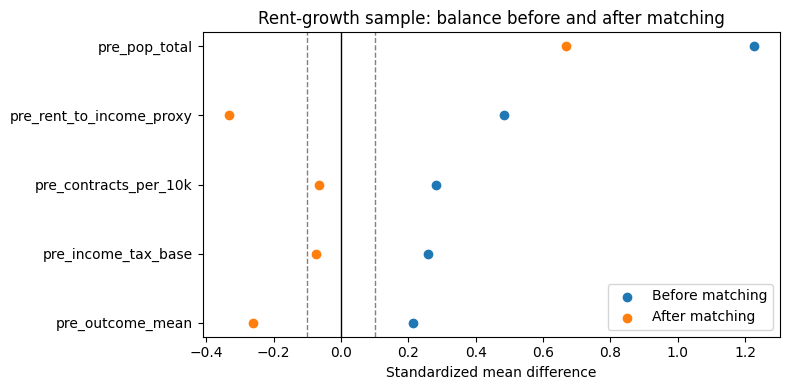

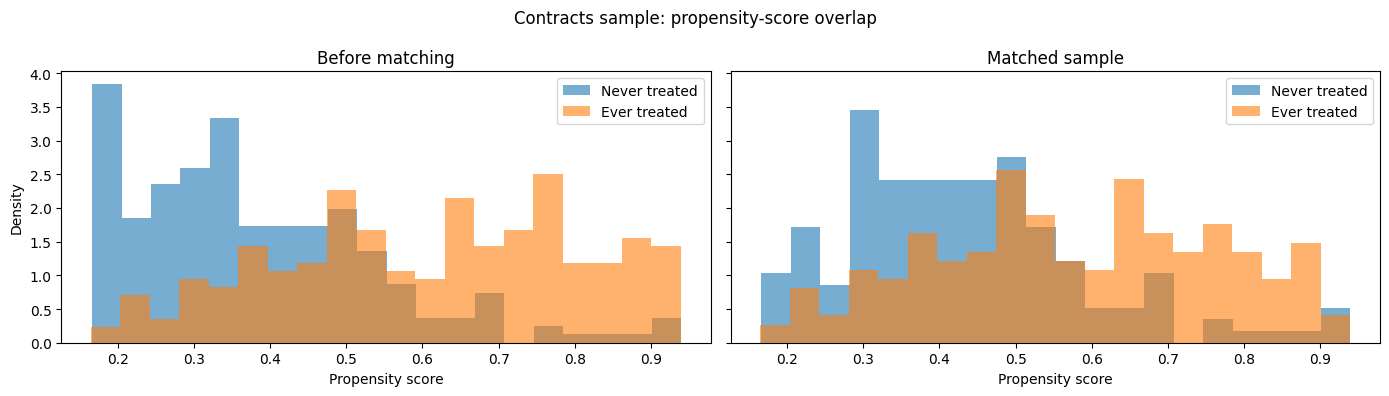

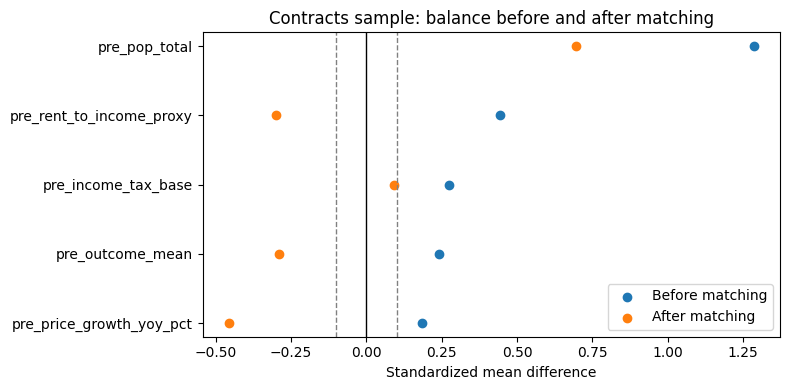

In [11]:
def plot_pscore_overlap(unit_ps, matched_units, title):
    fig, axes = plt.subplots(1, 2, figsize=(14, 4), sharey=True)
    for ax, df_plot, ttl in [
        (axes[0], unit_ps, "Before matching"),
        (axes[1], matched_units, "Matched sample"),
    ]:
        tr = df_plot[df_plot["ever_treated"] == 1]["pscore"]
        co = df_plot[df_plot["ever_treated"] == 0]["pscore"]
        ax.hist(co, bins=20, alpha=0.6, density=True, label="Never treated")
        ax.hist(tr, bins=20, alpha=0.6, density=True, label="Ever treated")
        ax.set_title(ttl)
        ax.set_xlabel("Propensity score")
        ax.legend()
    axes[0].set_ylabel("Density")
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()

def plot_love(balance_df, title):
    tmp = balance_df.copy().sort_values("smd_before", key=lambda s: s.abs(), ascending=True)
    plt.figure(figsize=(8, max(4, 0.45 * len(tmp))))
    plt.scatter(tmp["smd_before"], tmp["covariate"], label="Before matching")
    plt.scatter(tmp["smd_after"], tmp["covariate"], label="After matching")
    plt.axvline(0, color="black", lw=1)
    plt.axvline(0.1, color="grey", lw=1, linestyle="--")
    plt.axvline(-0.1, color="grey", lw=1, linestyle="--")
    plt.xlabel("Standardized mean difference")
    plt.ylabel("")
    plt.title(title)
    plt.legend()
    plt.tight_layout()
    plt.show()

plot_pscore_overlap(rent_results["unit_ps_common_support"], rent_results["matched_units"], "Rent-growth sample: propensity-score overlap")
plot_love(rent_results["balance"], "Rent-growth sample: balance before and after matching")

plot_pscore_overlap(contracts_results["unit_ps_common_support"], contracts_results["matched_units"], "Contracts sample: propensity-score overlap")
plot_love(contracts_results["balance"], "Contracts sample: balance before and after matching")

## Dynamic ATT(e) plots

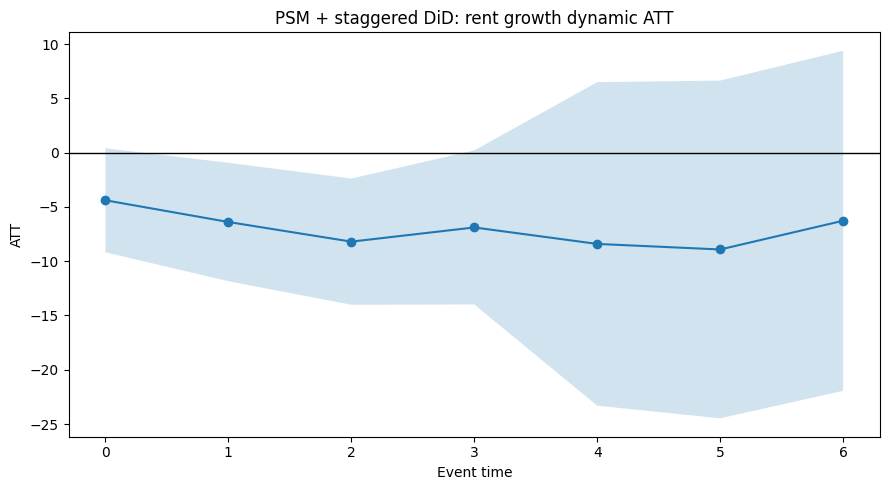

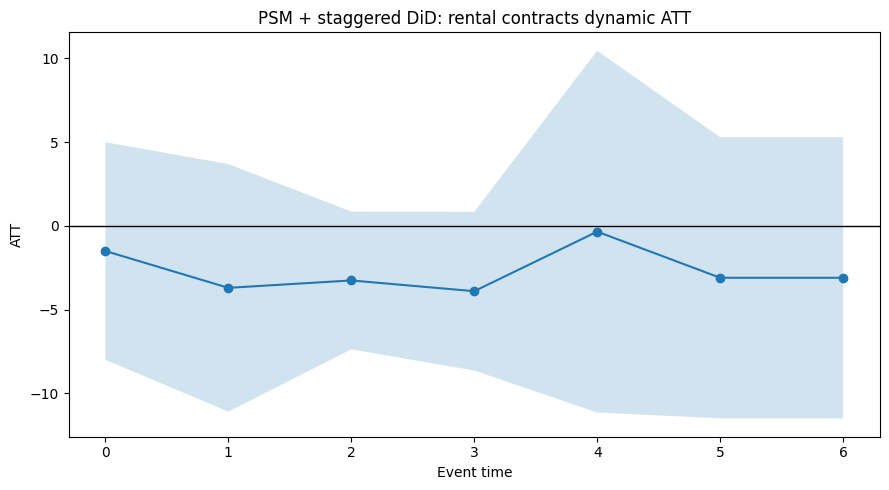

In [12]:
def plot_dynamic_att(dynamic_df: pd.DataFrame, title: str):
    if dynamic_df.empty:
        print(f"No dynamic ATT estimates available for: {title}")
        return
    d = dynamic_df.sort_values("event_time").copy()
    plt.figure(figsize=(9, 5))
    plt.plot(d["event_time"], d["att"], marker="o")
    if {"ci_low", "ci_high"}.issubset(d.columns):
        plt.fill_between(d["event_time"], d["ci_low"], d["ci_high"], alpha=0.2)
    plt.axhline(0, color="black", lw=1)
    plt.xlabel("Event time")
    plt.ylabel("ATT")
    plt.title(title)
    plt.tight_layout()
    plt.show()

plot_dynamic_att(rent_results["dynamic"], "PSM + staggered DiD: rent growth dynamic ATT")
plot_dynamic_att(contracts_results["dynamic"], "PSM + staggered DiD: rental contracts dynamic ATT")

In [20]:
summary_table = pd.concat([rent_results["summary"], contracts_results["summary"]], ignore_index=True)

paths = {
    "rent_balance_csv": OUT_DIR / "psm_csdid_rent_balance.csv",
    "contracts_balance_csv": OUT_DIR / "psm_csdid_contracts_balance.csv",
    "rent_units_csv": OUT_DIR / "psm_csdid_rent_matched_units.csv",
    "contracts_units_csv": OUT_DIR / "psm_csdid_contracts_matched_units.csv",
    "rent_pairs_csv": OUT_DIR / "psm_csdid_rent_match_pairs.csv",
    "contracts_pairs_csv": OUT_DIR / "psm_csdid_contracts_match_pairs.csv",
    "rent_att_gt_csv": OUT_DIR / "psm_csdid_rent_att_gt.csv",
    "contracts_att_gt_csv": OUT_DIR / "psm_csdid_contracts_att_gt.csv",
    "rent_dynamic_csv": OUT_DIR / "psm_csdid_rent_dynamic.csv",
    "contracts_dynamic_csv": OUT_DIR / "psm_csdid_contracts_dynamic.csv",
    "summary_csv": OUT_DIR / "psm_csdid_summary.csv",
    "summary_xlsx": OUT_DIR / "psm_csdid_summary.xlsx",
    "summary_tex": OUT_DIR / "psm_csdid_summary.tex",
}

rent_results["balance"].to_csv(paths["rent_balance_csv"], index=False)
contracts_results["balance"].to_csv(paths["contracts_balance_csv"], index=False)

rent_results["matched_units"].to_csv(paths["rent_units_csv"], index=False)
contracts_results["matched_units"].to_csv(paths["contracts_units_csv"], index=False)

rent_results["matched_pairs"].to_csv(paths["rent_pairs_csv"], index=False)
contracts_results["matched_pairs"].to_csv(paths["contracts_pairs_csv"], index=False)

rent_results["att_gt"].to_csv(paths["rent_att_gt_csv"], index=False)
contracts_results["att_gt"].to_csv(paths["contracts_att_gt_csv"], index=False)

rent_results["dynamic"].to_csv(paths["rent_dynamic_csv"], index=False)
contracts_results["dynamic"].to_csv(paths["contracts_dynamic_csv"], index=False)

summary_table.to_csv(paths["summary_csv"], index=False)
summary_table.to_excel(paths["summary_xlsx"], index=False)
paths["summary_tex"].write_text(summary_table.to_latex(index=False, escape=False, float_format="%.4f"), encoding="utf-8")

print("Saved:")
for p in paths.values():
    print(" -", p)

display(summary_table)

Saved:
 - /home/venatio/documents/university/public-sector-2026/out/psm_csdid_rent_balance.csv
 - /home/venatio/documents/university/public-sector-2026/out/psm_csdid_contracts_balance.csv
 - /home/venatio/documents/university/public-sector-2026/out/psm_csdid_rent_matched_units.csv
 - /home/venatio/documents/university/public-sector-2026/out/psm_csdid_contracts_matched_units.csv
 - /home/venatio/documents/university/public-sector-2026/out/psm_csdid_rent_match_pairs.csv
 - /home/venatio/documents/university/public-sector-2026/out/psm_csdid_contracts_match_pairs.csv
 - /home/venatio/documents/university/public-sector-2026/out/psm_csdid_rent_att_gt.csv
 - /home/venatio/documents/university/public-sector-2026/out/psm_csdid_contracts_att_gt.csv
 - /home/venatio/documents/university/public-sector-2026/out/psm_csdid_rent_dynamic.csv
 - /home/venatio/documents/university/public-sector-2026/out/psm_csdid_contracts_dynamic.csv
 - /home/venatio/documents/university/public-sector-2026/out/psm_csdid

,Outcome,att,n_cells,n_treated_weight,se,z,p_value,ci_low,ci_high,att_stars,N municipalities (matched),N treated (matched),N controls (matched),Matching,Caliper rule,Control group,Estimation window,Bootstrap reps
0,"Rent growth (YoY, pp)",-6.7687,11,"1,030.0000",3.0257,-2.2371,0.0253,-12.6991,-0.8384,-6.7687**,361,202,159,"3:1 nearest-neighbor, replacement",0.10 * SD(logit pscore),Never treated only,2022Q1-2025Q4,199
1,Tenancy agreements per 10k,-2.9048,11,956.0000,2.4477,-1.1867,0.2353,-7.7024,1.8928,-2.9048,341,191,150,"3:1 nearest-neighbor, replacement",0.10 * SD(logit pscore),Never treated only,2022Q1-2025Q4,199



## Notes for interpretation

- This notebook uses **never-treated matched controls only**
- Matching is based only on **common pre-treatment municipality averages**
- Inference uses a **municipality-level bootstrap**, and **matching is re-estimated inside each bootstrap draw**
- The overall ATT is a weighted average of cohort-time ATT(g,t) cells using the treated-cell size as the aggregation weight

This makes the design substantially more stringent than the baseline TWFE table, while still keeping the estimator fully transparent.
